# Window visualiser

Plot a test patient's 10 s windows next to the spectrogram the model received, with the
true label, prediction and P(AF). Green = correct, red = misclassified.

- `dataset`: `'afdb'`, `'icentia_100'` or `'icentia_zeroshot'` (see `DATASETS` in `infrastructure/visual.py`)
- `fold`: the fold whose **test** set contains the patient (for `icentia_zeroshot`, it picks the AFDB checkpoint)
- `run`: optional, a different results folder (e.g. `run='bgm_afdb_1_authcopy'`)
- Icentia11k needs the Seagate mounted.

In [17]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from infrastructure.visual import load_patient, patient_summary, plot_windows

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Choose a patient

In [9]:
dataset, fold, patient = 'icentia_100', 2, 'p00060'
patient_summary(dataset, fold, patient)

FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/seagate_hard/icentia_100_npz/p00006.npz'

## Misclassified windows

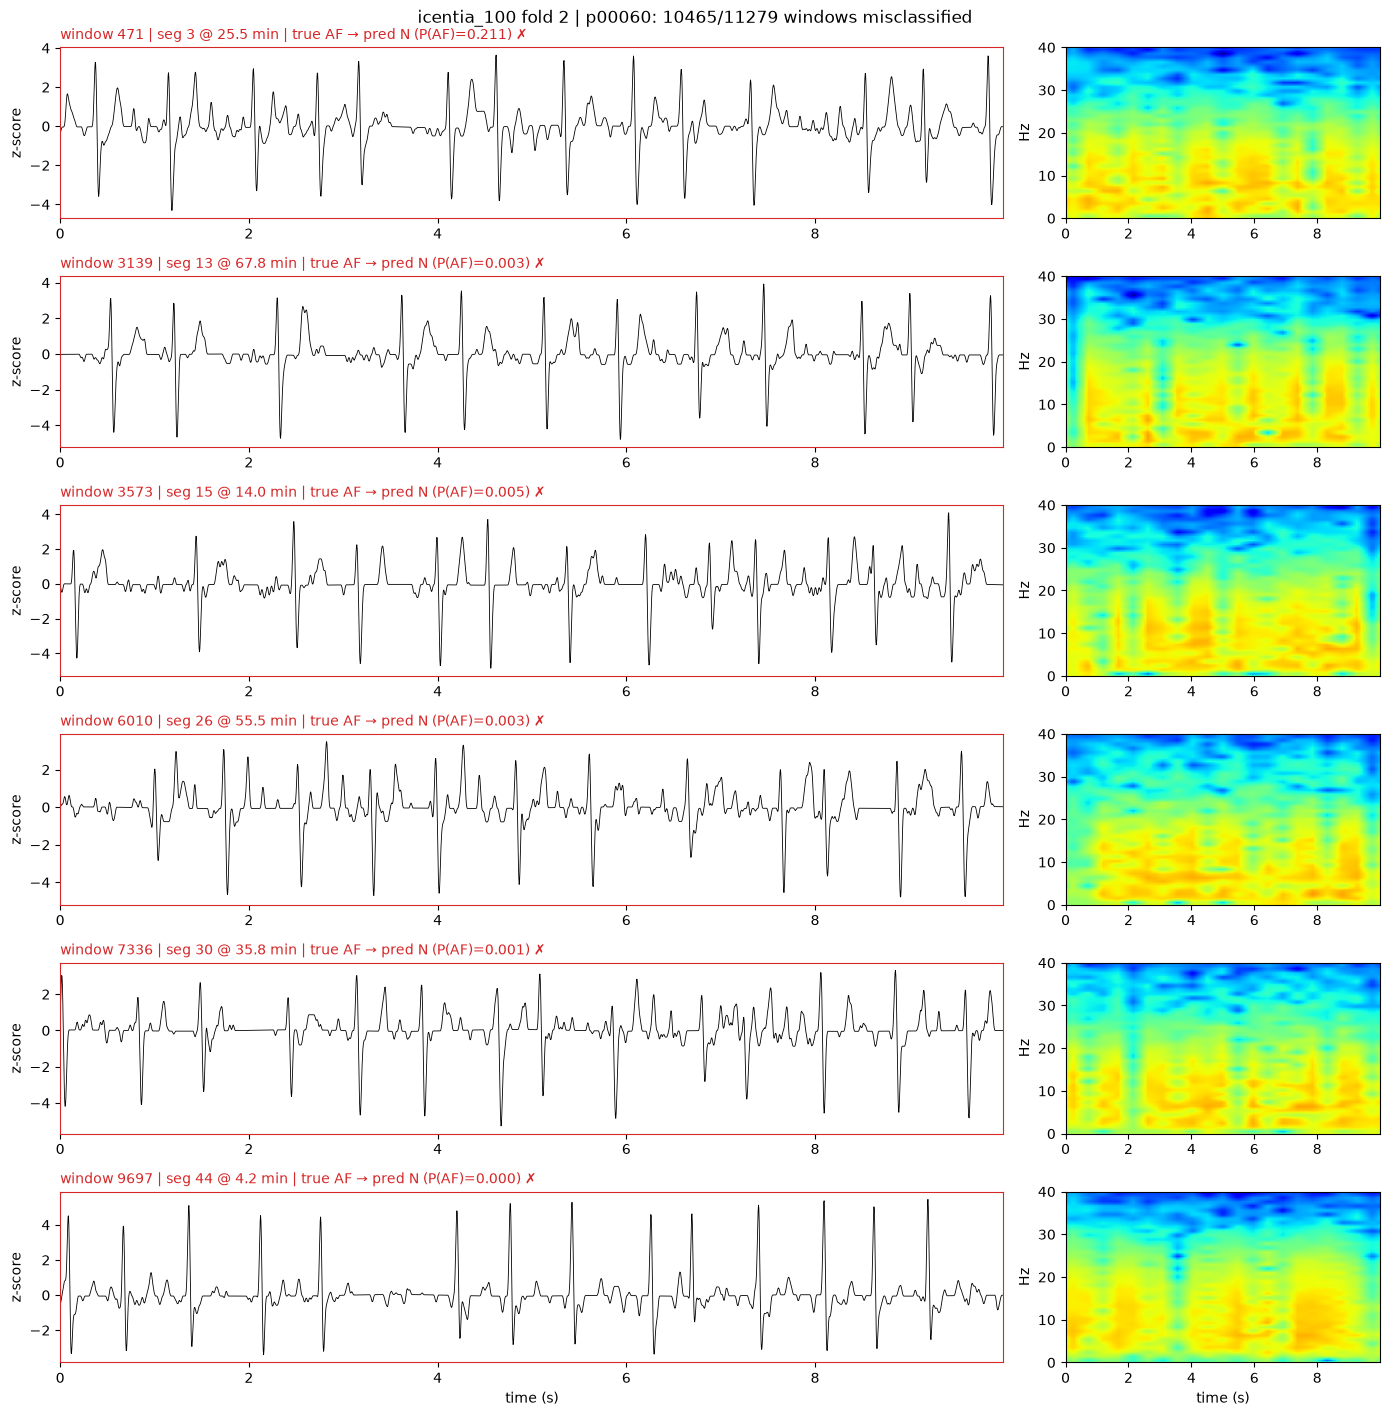

,true,pred,p_AF,correct,seg_idx,start_sample
471,AF,N,0.210879,False,3,382500
3139,AF,N,0.003361,False,13,1017500
3573,AF,N,0.005363,False,15,210000
6010,AF,N,0.003296,False,26,832500
7336,AF,N,0.001358,False,30,537500
9697,AF,N,0.000107,False,44,62500


In [ ]:
plot_windows(dataset, fold, patient, show='incorrect', n=6)

## Correctly classified windows (for comparison)

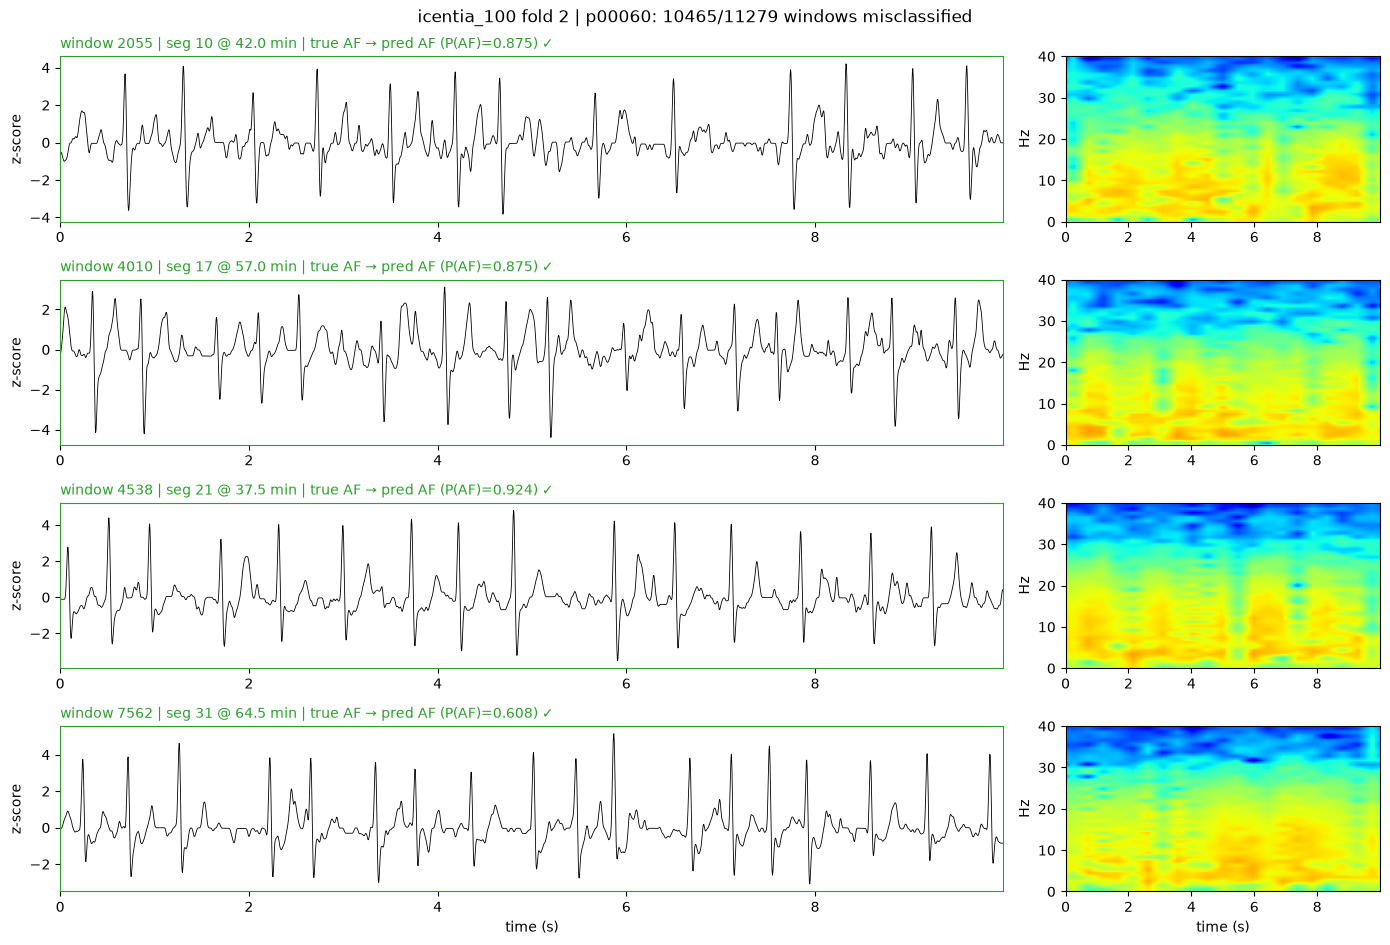

,true,pred,p_AF,correct,seg_idx,start_sample
2055,AF,AF,0.874904,True,10,630000
4010,AF,AF,0.875418,True,17,855000
4538,AF,AF,0.923518,True,21,562500
7562,AF,AF,0.608320,True,31,967500


In [ ]:
plot_windows(dataset, fold, patient, show='correct', n=4)

## Specific windows
Use the row numbers from `load_patient`'s table, e.g. the least confident ones.

In [8]:
segments, table = load_patient('afdb', fold, patient)
table.sort_values('p_AF').query('true == "AF"').head(10)

NameError: name 'fold' is not defined

In [ ]:
plot_windows(dataset, fold, patient, windows=[0, 1, 2])

KeyError: 'cpsc'

# Windows discarded in preprocessing

Windows that were 100% AF or 100% N but removed by the quality check (zhao2018, "Unacceptable" or an
R-peak detection error), shown after the same filtering and z-scoring as the kept ones.
The table above the plots gives kept vs discarded counts per class for the record.

- `source`: `'afdb'`, `'cpsc'` or `'icentia'` (Icentia needs the Seagate mounted)
- `record`: AFDB record (`'04043'`), CPSC case (`'46'`) or file (`'data_46_5'`), Icentia patient (`'p00060'`)
- `label='AF'` / `'N'` to show one class; `n` and `seed` choose the sample

afdb 06426: windows kept vs discarded by the quality check


,kept,discarded,discarded %
AF,83,3404,97.6
N,16,111,87.4


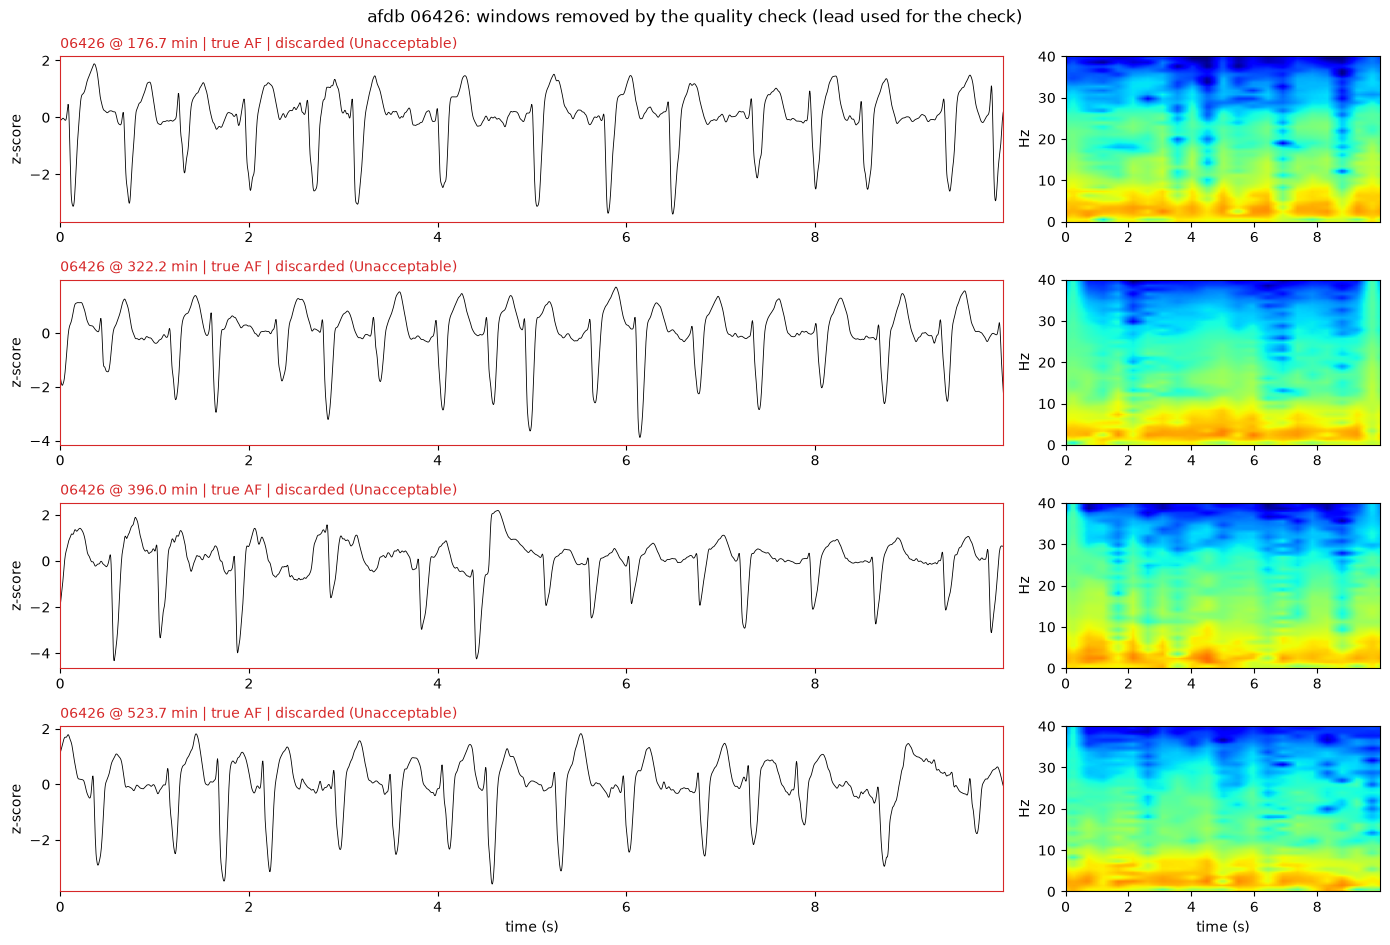

cpsc 46: windows kept vs discarded by the quality check


,kept,discarded,discarded %
N,2749,78,2.8


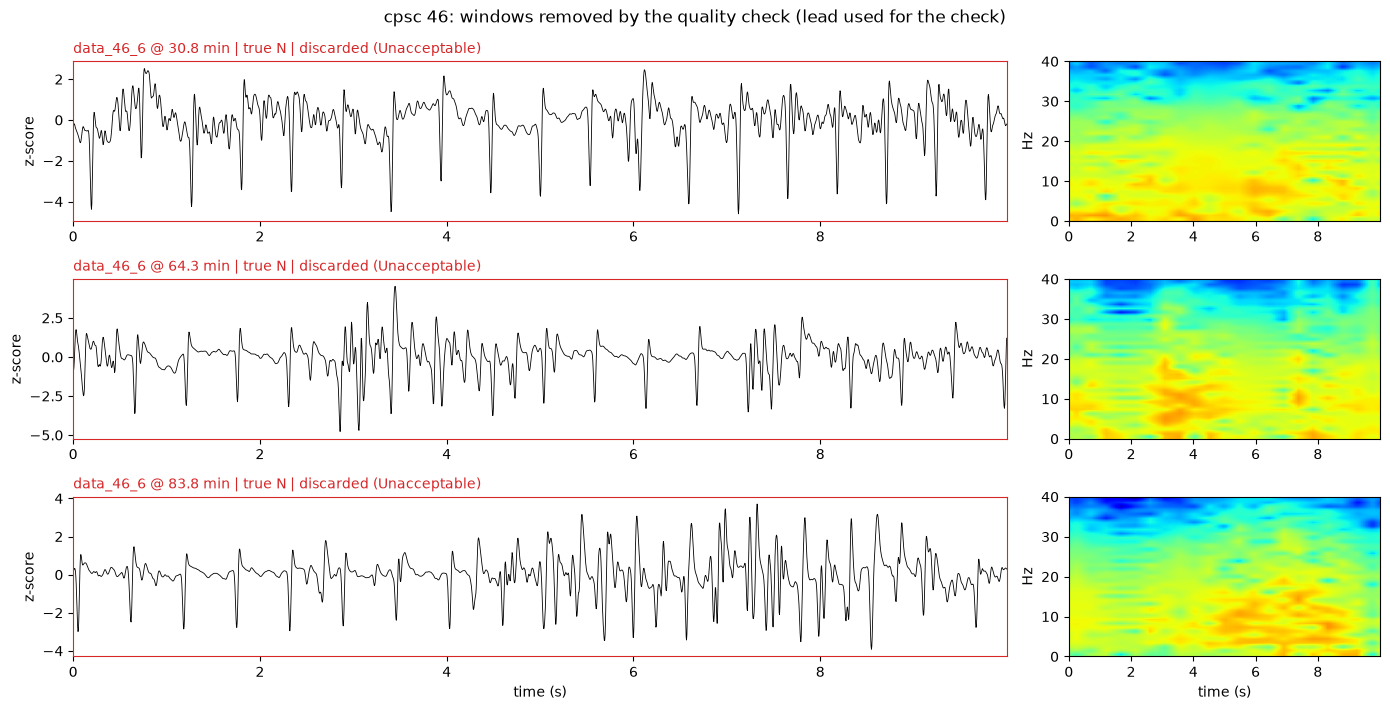

(   kept  discarded  discarded %
 N  2749         78          2.8,
          file  start_sample     minute true   fs         grade
 39  data_46_6        370030  30.835833    N  200  Unacceptable
 49  data_46_6        772030  64.335833    N  200  Unacceptable
 64  data_46_6       1006030  83.835833    N  200  Unacceptable)

In [10]:
from infrastructure.visual import plot_discarded

plot_discarded('afdb', '06426', n=4)               # AFDB: 69% of AF and 97% of N candidate windows were dropped
plot_discarded('cpsc', '46', n=3)                  # CPSC case 46 (one of the cases with the most errors)
# plot_discarded('icentia', 'p00060', n=4)         # needs the Seagate mounted

# Atrial flutter windows

100% AFL windows that passed the same quality check as AF/N (made by `preprocess/segment_BIHAF_afl.py` and
`segment_CPSC2021_afl.py`). No model has seen them, so there are no predictions. `compare=True` adds one kept
AF and one kept N window from the same record. AFDB records with AFL windows: 04936 (128), 07910 (47), 08215 (4),
04908 (1). CPSC: almost all from case 25 (`data_25_*`).

,AFL,AF,N
record,,,
04043,0,219,95
04908,1,229,3332
04936,128,2563,653
06426,0,83,16
06995,0,1722,1942
07910,47,580,3044
08215,4,2944,708
08378,0,108,1502
Total,180,8448,11292


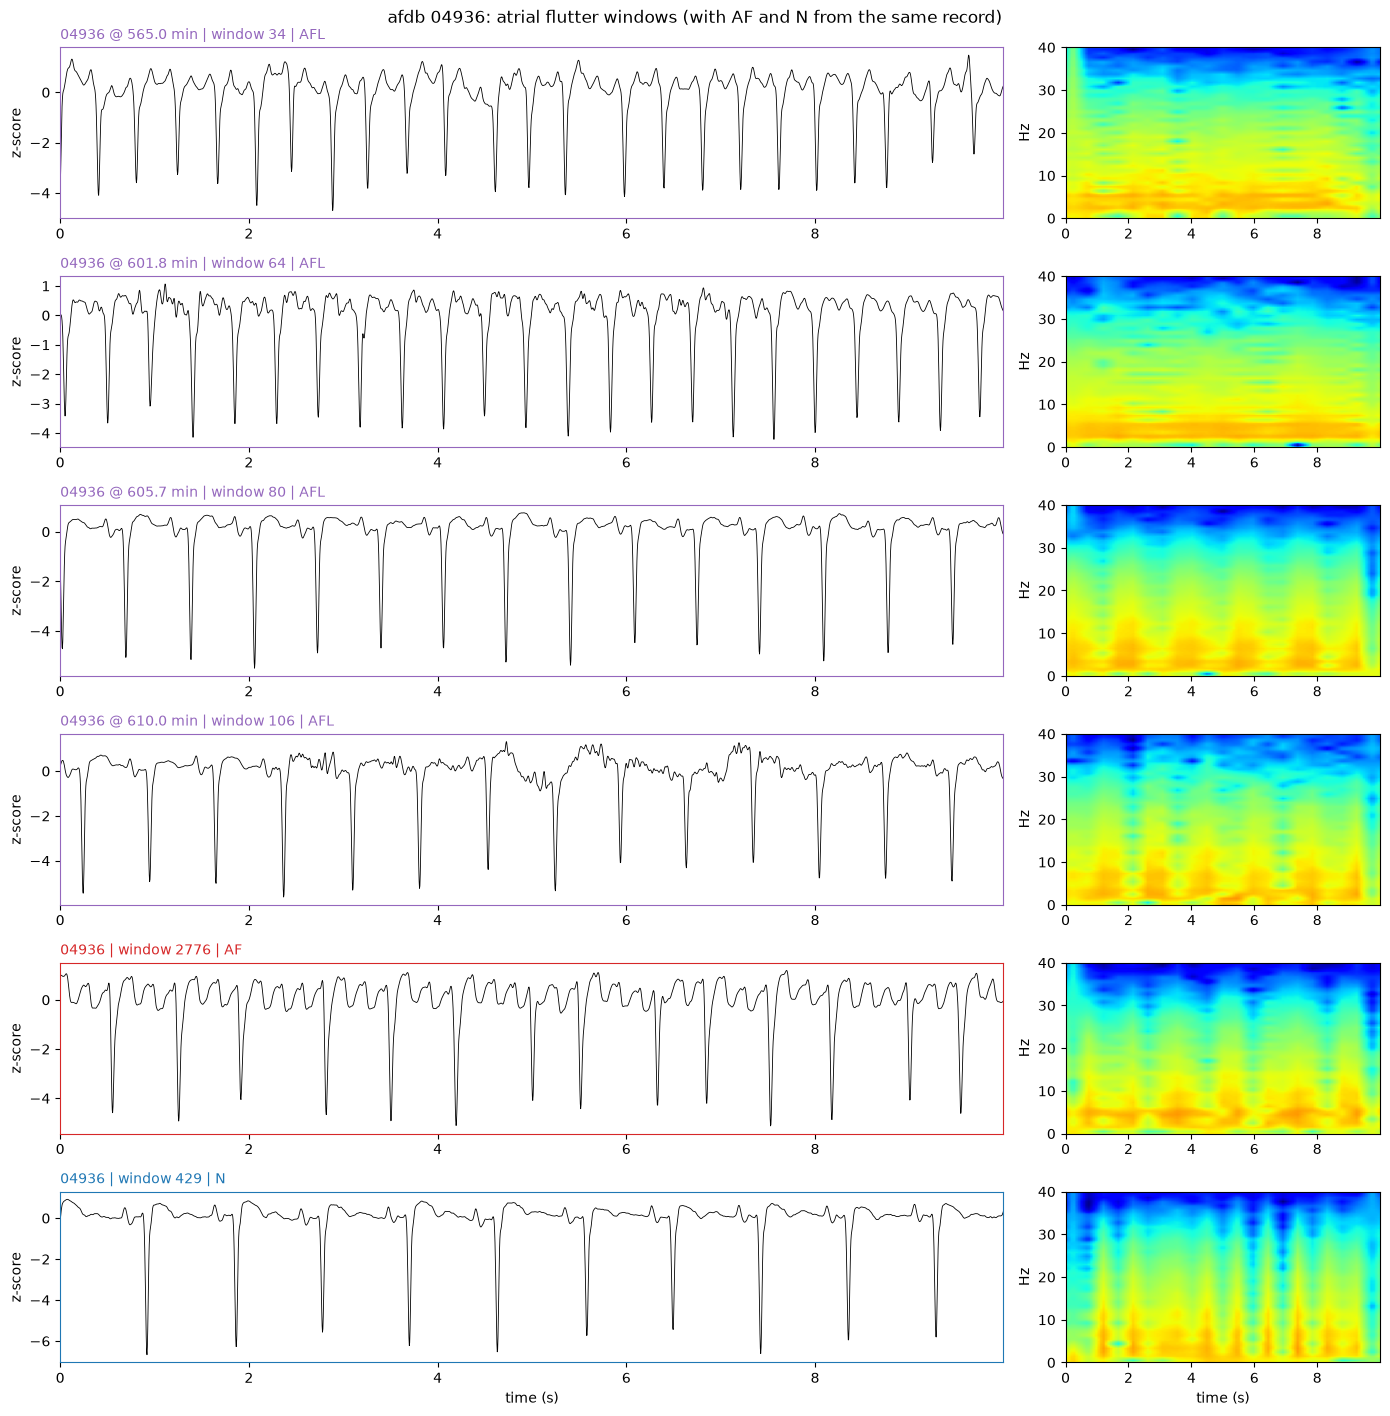

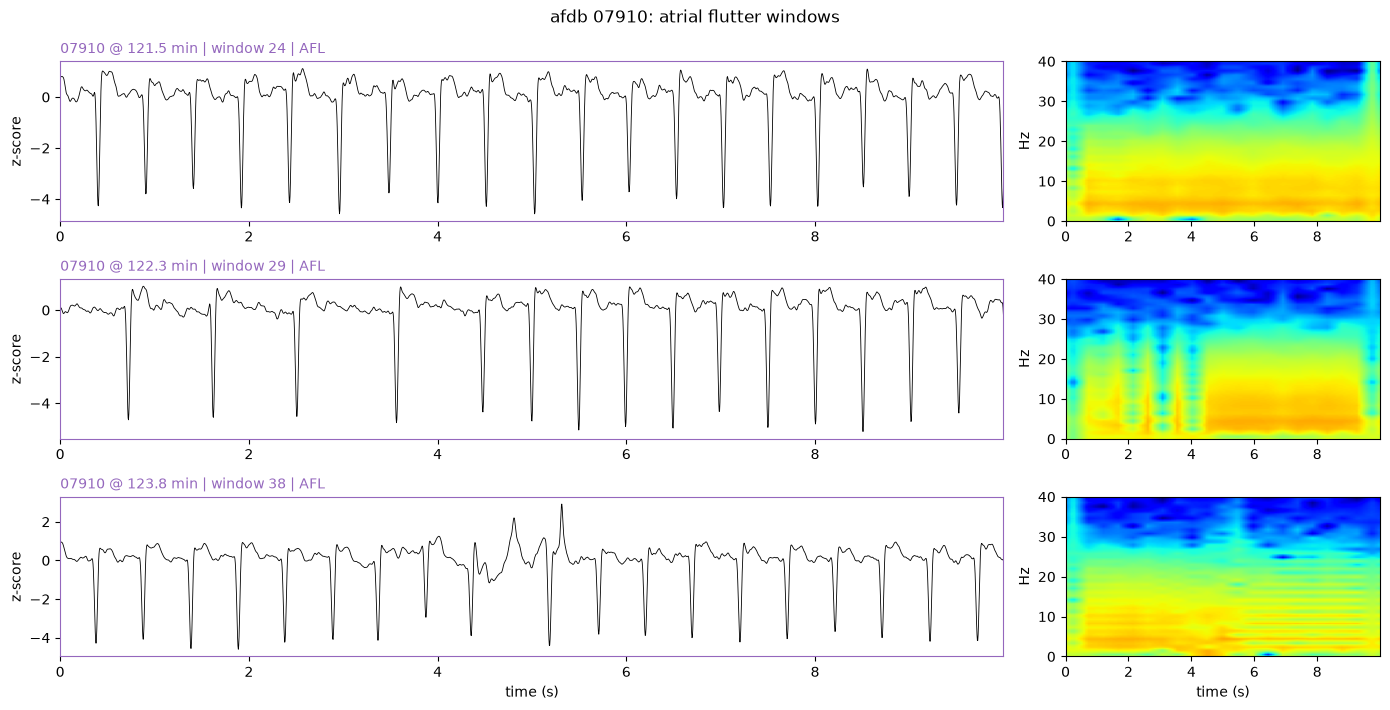

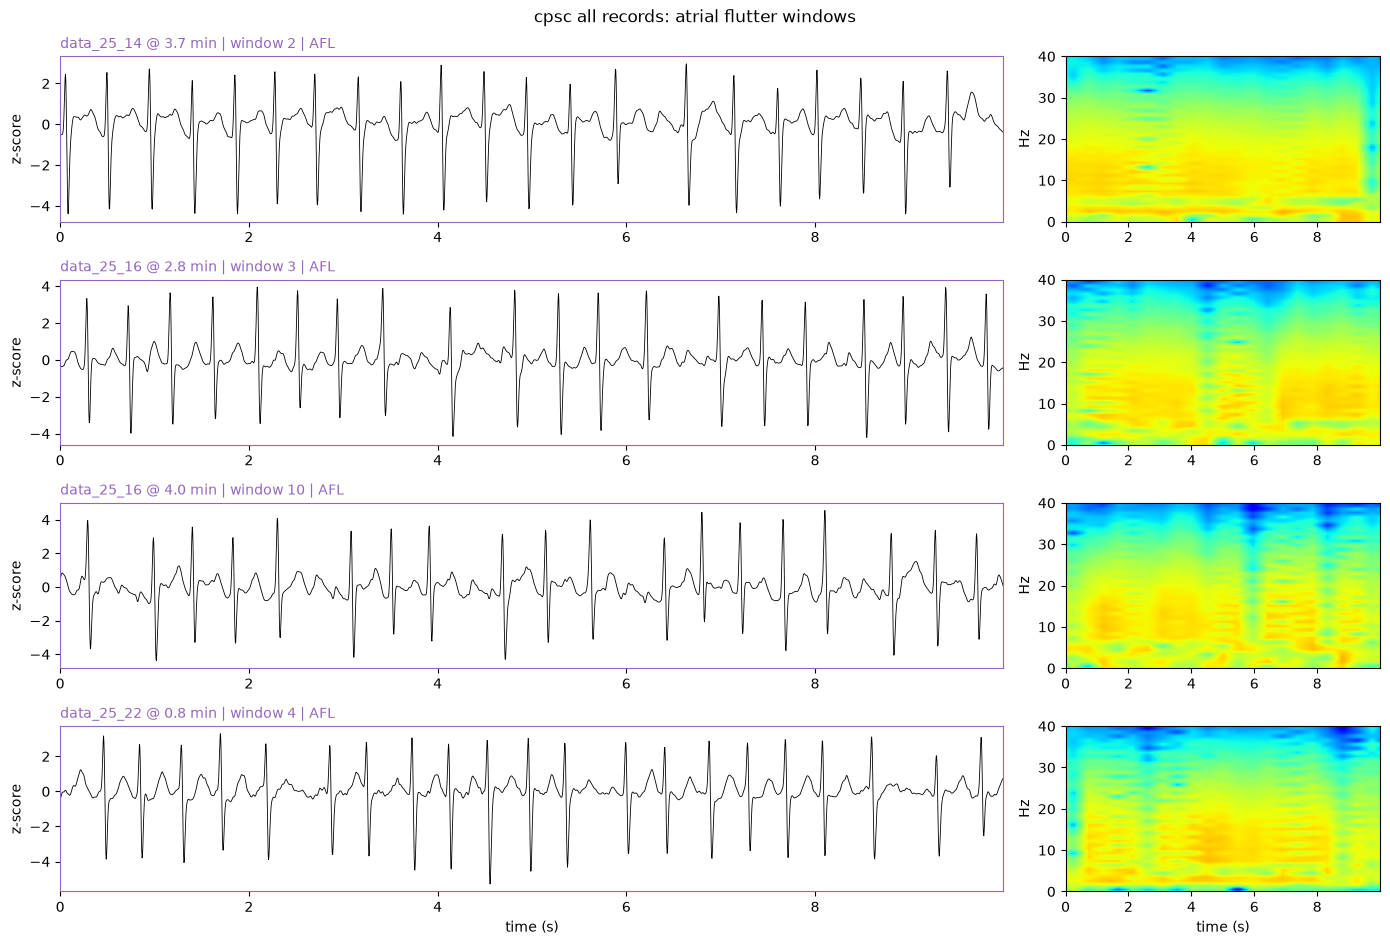

,record,index,true,minute
0,data_25_14,2,AFL,3.669167
1,data_25_16,3,AFL,2.835833
2,data_25_16,10,AFL,4.002500
3,data_25_22,4,AFL,0.835833


In [12]:
from infrastructure.visual import afl_summary, plot_afl

display(afl_summary('afdb'))
plot_afl('afdb', '04936', n=4, compare=True)   # flutter vs AF vs N in the same patient
plot_afl('afdb', '07910', n=3)
plot_afl('cpsc', n=4)                          # sampled across all CPSC files

# Grad-CAM

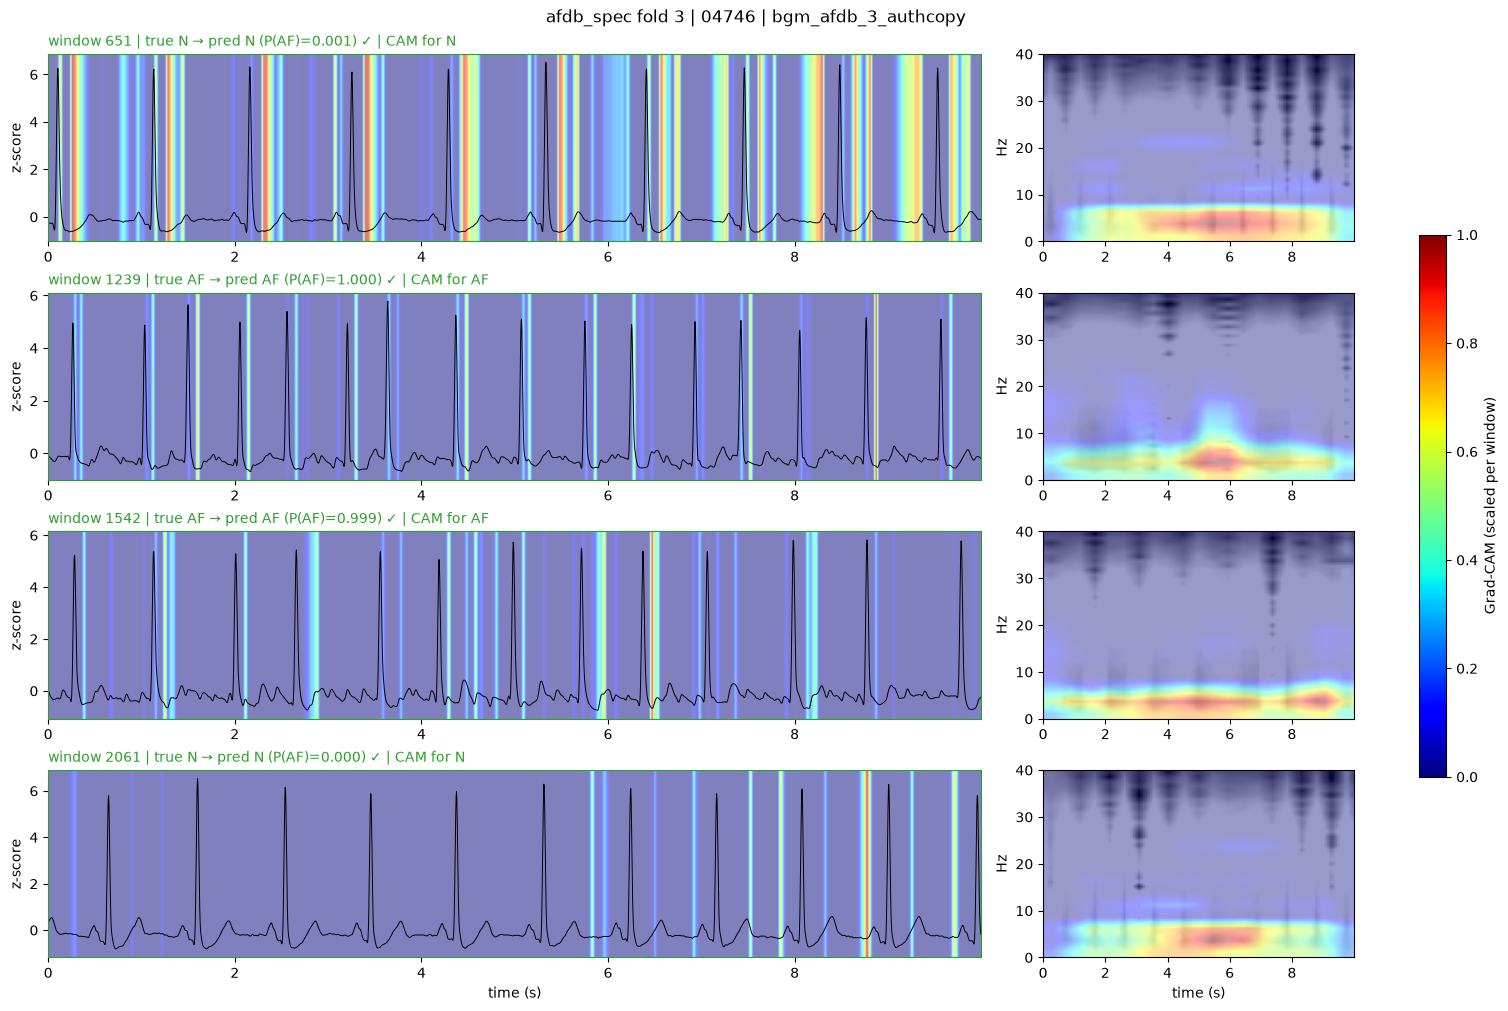

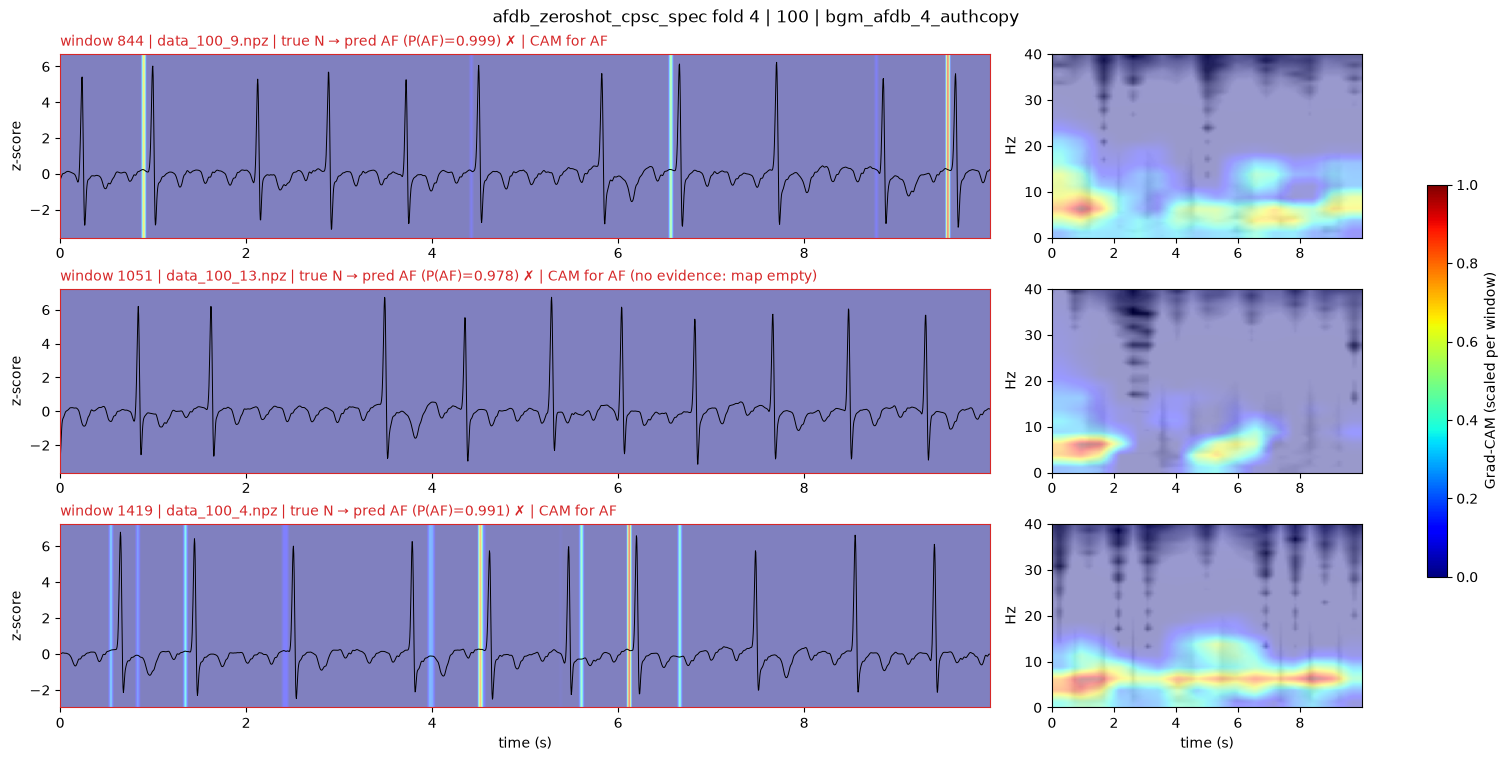

In [ ]:
from infrastructure.visual import plot_gradcam, gradcam_windows

plot_gradcam('afdb_spec', 3, '04746', show='correct', n=4)               # explain the model's prediction, as in the paper
plot_gradcam('afdb_zeroshot_cpsc_spec', 4, '100', n=3, target='AF')        # CPSC case 100, "what looks like AF?"
rows, maps = gradcam_windows('afdb_acc', 2, '04015', windows=[10, 11])

In [ ]:
from infrastructure.visual import explorer
explorer()


# t-SNE of penultimate-layer features

As in MGCNet (arXiv v2, Fig. 7): features from the penultimate layer (the 128-d hidden layer of the classifier) for
the fold's in-domain test windows and for the other dataset (cross-domain, e.g. `CPSC_AFDB` = CPSC-trained model on AFDB),
coloured by class and domain, with KDE contours (densest 50% / 90%) and 2σ covariance ellipses.

- `layer`: `'penultimate'` (128-d), `'fused'` (512-d), `'time'` / `'freq'` (256-d contrastive embeddings)
- `afl=True` adds the flutter windows of the same records
- `exclude_val=True` leaves out the cross-domain records used for validation in this fold, so they are unseen
- The table gives numbers in the original feature space (t-SNE distorts distances): class silhouette, and how well a
  k-NN tells the two domains apart within a class (0.5 = mixed, 1 = separate clusters)
- `mark_errors=True` rings misclassified AF/N windows. `interactive=True` draws with plotly: hovering a point shows its
  dataset, patient, file, segment (row in that npz; start time for AFL windows), prediction and P(AF). Click legend
  entries to hide a group.
- With `interactive=True`, **click a point** (e.g. a ringed misclassified one) to show its ECG and spectrogram below the plot.
  Tick *Grad-CAM* to overlay the heatmaps, and choose what to explain (prediction, true class, AF or N). If clicking doesn't
  work, `plot_tsne_window(tsne_table, i, checkpoint_path(dataset, fold), gradcam=True)` shows row `i` of `tsne_table`.

In [2]:
from infrastructure.visual import plot_tsne

mark_errors = True     # ring the AF/N windows the model misclassifies
interactive = True     # plotly: hover for dataset/patient/segment, click for ECG + spectrogram (+ Grad-CAM)

# CPSC-trained model: CPSC (in-domain) vs CPSC_AFDB (cross-domain), as in the paper (about 1 min)
emb, tsne_table, separation = plot_tsne('cpsc', 3, layer='penultimate', n_per_class=300,
                                        mark_errors=mark_errors, interactive=True)
display(separation)

# AFDB-trained model with flutter (fold 4's test records include 04936)
emb, tsne_table, separation = plot_tsne('afdb_acc', 4, afl=True, mark_errors=mark_errors, interactive=interactive)
display(separation)

# misclassified windows, to look at with plot_windows / plot_gradcam
tsne_table[tsne_table['true'].isin(['N', 'AF']) & (tsne_table['pred'] != tsne_table['true'])]

    'data': [{'hoverinfo': 'text',
              'hovertext': array(['<b>CPSC N<…

,measure,subset,value
0,class silhouette (N vs AF),all,0.466
1,class silhouette (N vs AF),CPSC,0.483
2,class silhouette (N vs AF),CPSC_AFDB,0.467
3,"domain kNN acc (k=10, 5-fold)",AF,0.553
4,"domain kNN acc (k=10, 5-fold)",N,0.502


    'data': [{'hoverinfo': 'text',
              'hovertext': array(['<b>AFDB N<…

,measure,subset,value
0,class silhouette (N vs AF),all,0.539
1,class silhouette (N vs AF),AFDB,0.569
2,class silhouette (N vs AF),AFDB_CPSC,0.525
3,"domain kNN acc (k=10, 5-fold)",AF,0.707
4,"domain kNN acc (k=10, 5-fold)",AFL,0.928
5,"domain kNN acc (k=10, 5-fold)",N,0.680


,domain,set,dataset,patient,file,window,minute,true,pred,p_AF
12,in,AFDB,AFDB,04043,04043,132,NaN,N,AF,0.999297
32,in,AFDB,AFDB,04048,04048,10,NaN,AF,N,0.036195
43,in,AFDB,AFDB,04048,04048,181,NaN,N,AF,0.580236
46,in,AFDB,AFDB,04048,04048,227,NaN,N,AF,0.806658
47,in,AFDB,AFDB,04048,04048,231,NaN,N,AF,0.912540
...,...,...,...,...,...,...,...,...,...,...
1282,cross,AFDB_CPSC,CPSC,91,data_91_18,91,NaN,AF,N,0.023920
1287,cross,AFDB_CPSC,CPSC,91,data_91_1,168,NaN,AF,N,0.382874
1288,cross,AFDB_CPSC,CPSC,91,data_91_1,188,NaN,AF,N,0.269630
1289,cross,AFDB_CPSC,CPSC,91,data_91_1,431,NaN,AF,N,0.135745


# Training runs

TensorBoard logs in `BGM_GitHub/new_runs/runs/<title>/` (mine), `BGM_GitHub/runs/` (the author's, `source='author'`) and
`trials/icentia_runs/runs/` (Icentia11k). Full numbers and notes: `BGM_GitHub/new_runs/runs.md` and `BGM_GitHub/replication_trials/*/README.md`.

**Shared settings** unless stated: MacBook MPS, batch 128, up to 25 epochs, early stopping after 10 epochs without a better validation
accuracy, Adam lr 1e-3 with InverseTimeLR, total loss = CE + λ·SCL with λ = 0.01, random vertical flip in augmentation, seed 3407.
The kept checkpoint is the epoch with the best validation accuracy. *Best val* = that accuracy (%) @ epoch; *Test* = accuracy on the
fold's held-out records.

**Suffixes:** none = my MGCNet-Research pipeline · `_authcopy` = the author's January code and config · `_oldcpsc` = validated on the
CPSC2021 set made with neurokit2 0.2.13 (140,312 windows) instead of the corrected 0.2.12 set (137,010) · `_exact` / `_ex_*` = the author's
December settings · `_seedN` = same config, another seed.

### AFDB five-fold (train on AFDB fold-k training records, test on its held-out records)

| Runs | Validation set | What it tests | Folds: epochs, best val, test acc |
|---|---|---|---|
| `bgm_afdb_1`–`5` | CPSC fold k (old) | My pipeline; folds 4–5 at lr 1e-4 | 1: 19, 91.86@9, .9866 · 2: 25, 93.72@25, .8644 · 3: 25, 91.45@21, .8662 · 4: 25, 89.61@18, .8748 · 5: 25, 94.72@19, .9359 |
| `bgm_afdb_2_ce` | CPSC fold 2 (old) | No contrastive loss (λ = 0) | 20, 86.07@10, .8590 |
| `bgm_afdb_k_authcopy_oldcpsc` | CPSC fold k (old) | Author's code; identical to mine for folds 1–3 | 1: .9866 · 2: .8644 · 3: .8662 · 4: 17, 86.93@7, .9335 · 5: 20, 94.86@10, .8737 |
| `bgm_afdb_k_authcopy` | CPSC fold k (corrected) | Main replication | 1: 18, 91.74@8, .9928 · 2: 25, 91.56@19, .8153 · 3: 21, 87.48@11, .8278 · 4: 25, 88.27@21, .9161 · 5: 22, 94.74@12, .8993 |
| `bgm_afdb_4_authcopy_seed2`, `_seed3` | CPSC fold 4 | Run-to-run spread of fold 4 | seed 2: 25, 87.65@25, .9209 · seed 3: 22, 88.26@12, .8825 |
| `bgm_afdb_k_afdb_only` | none (last epoch kept) | No validation, no vertical flip: fully zero-shot on CPSC | 1: .9989 · 2: .9475 · 3: .9458 · 4: .8833 · 5: .8441 (25 epochs each) |
| `bgm_afdb_{4,5}_authcopy_exact` | CPSC fold k | Author's December settings (lr 1e-4) | 4: 25, 88.63@18, .8759 · 5: 25, 93.83@22, .8531 |
| `bgm_afdb_{4,5}_authcopy_ex_minCPSC` | none (last epoch kept) | December settings without validation | 4: .8472 · 5: .8242 (25 epochs each) |
| `bgm_afdb_{2..5}_authcopy_ex_afdbval` | 3 held-out AFDB training records | December settings, AFDB validation | 2: 25, 99.29@23, .8895 · 3: 19, 76.79@9, .7121 · 4: 11, 87.95@1, .9160 · 5: 13, 89.01@3, .7980 |
| `bgm_afdb_1_authexact` | AFDB test fold | Author's December code, 256×256 spectrograms | Aborted in epoch 1 (out of memory); empty log |

Author's AFDB test accuracy for comparison: .9989 / .9817 / .9858 / .9748 / .9980.

### CPSC2021 five-fold (train on CPSC fold-k training cases, test on its held-out cases)

Configs `replication_trials/authcopy_cpsc/bgm_cpsc_k.yaml`; validation = AFDB fold-k held-out records (so *Best val* is AFDB accuracy).

| Run | Epochs | Best val | Test acc |
|---|---|---|---|
| `bgm_cpsc_1_authcopy` | 25 | 99.70@16 | .9718 |
| `bgm_cpsc_2_authcopy` | 25 | 93.99@23 | .9617 |
| `bgm_cpsc_3_authcopy` | 25 | 97.60@17 | .9114 |
| `bgm_cpsc_4_authcopy`, attempt 1 (seed 3407, 20 Nov) | 12 (early stop) | 96.59@2 | .7807 (checkpoint and results overwritten by attempt 2) |
| `bgm_cpsc_4_authcopy`, attempt 2 (seed 2, 21 Nov) | 19 (early stop) | 95.41@9 | .8939, the first run with CE / SCL logged separately |
| `bgm_cpsc_5_authcopy` | 21 (early stop) | 97.65@11 | .8747 |

Author's CPSC test accuracy: .9813 / .9824 / .9816 / .9836 / .9718.

### Other
- `icentia_100/bgm_icentia_100_{1,2}`: trained and tested on a 100-patient Icentia11k sample (no validation set).
- Author's logs (`source='author'`): `bgm_afdb_1`–`5`, `bgm_cpsc_1`–`5` and `*_visual`, with many attempts each (e.g. 42 for `bgm_afdb_1`;
  attempt 42, 17 Dec 03:25, made the published fold-1 checkpoint). Their losses are on a different scale in early attempts.

,source,started,epochs,best valid acc,CE/SCL parts,file
attempt,,,,,,
1,mine,20 Nov 2026 20:34,12,96.59@2,False,events.out.tfevents.1795206891.Tristans-MacBoo...
2,mine,21 Nov 2026 22:54,19,95.41@9,True,events.out.tfevents.1795301687.Tristans-MacBoo...


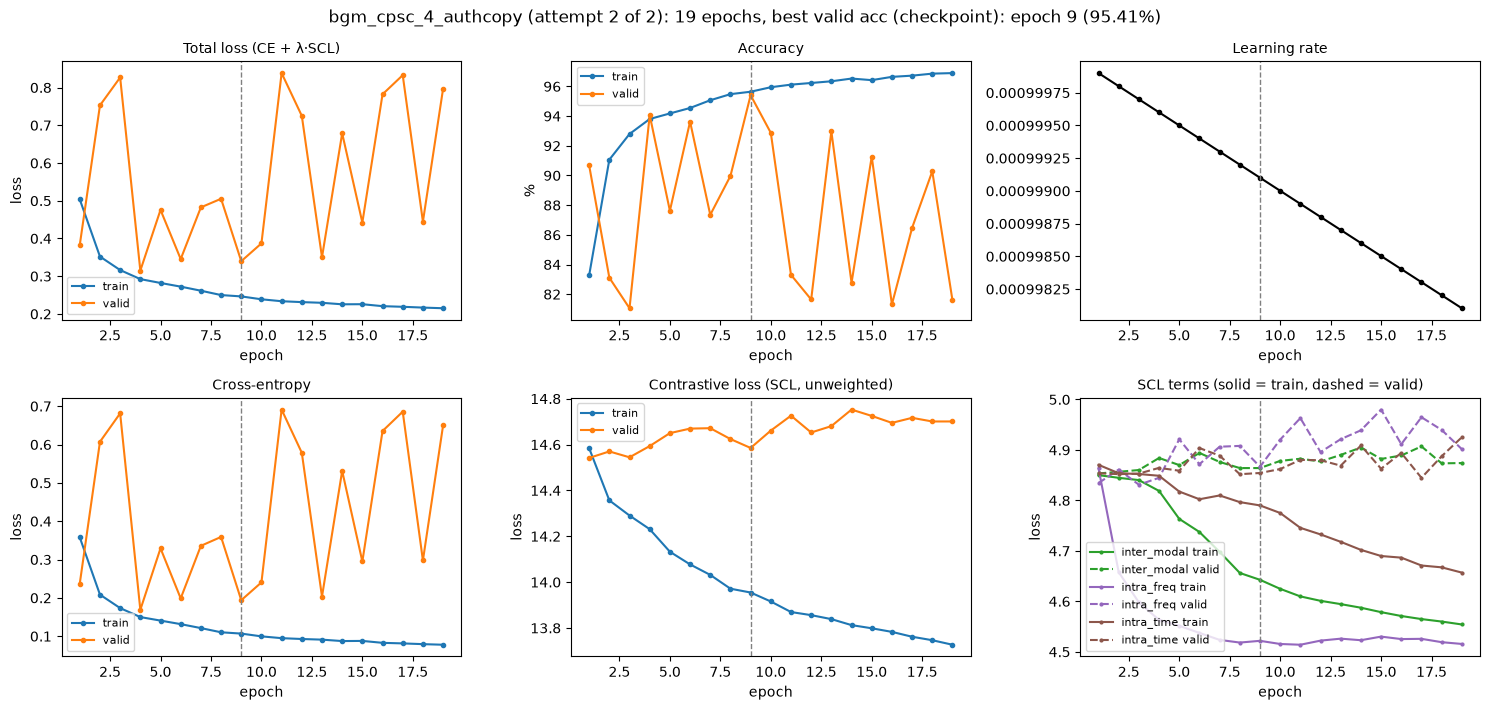

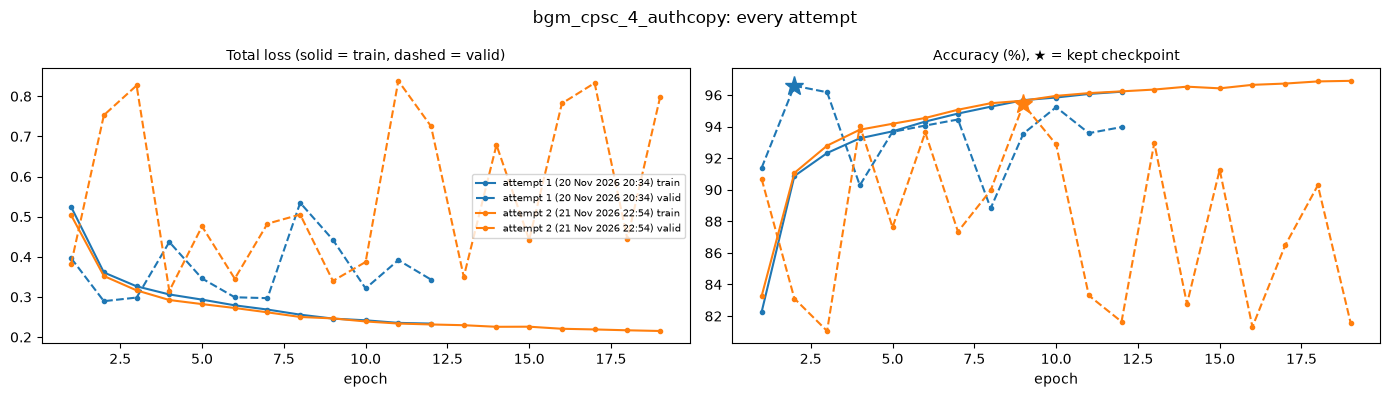

In [1]:
from infrastructure.curves import list_runs, attempts, plot_losses

run = 'bgm_cpsc_4_authcopy'        # any title from the tables above; list_runs() shows every logged run
source = None                       # None = search mine, then the author's, then Icentia; or 'mine' / 'author' / 'icentia'

display(attempts(run, source))      # one row per time this title was trained
curves = plot_losses(run, attempt=-1, source=source)   # -1 = latest attempt; 1, 2, ... for earlier ones
plot_losses(run, attempt='all', source=source);        # every attempt overlaid (total loss and accuracy)